# Movie Review Sentiment

This is an NLP classification project.

The file has 50000 movie reviews labeled positive or negative. The classes are already balanced. I will plot class counts, word counts and word clouds, then train two models on the same split. The first is Logistic Regression on TF-IDF. The second is an LSTM with a learned embedding. Reviews are longer than an SMS and the feeling of a sentence often depends on word order, so the LSTM is the deep model I want here. I will compare accuracy and F1, plot the confusion matrices, and save the LSTM.


In [1]:
import kagglehub

path = kagglehub.dataset_download("lakshmi25npathi/imdb-dataset-of-50k-movie-reviews")
print("Path to dataset files:", path)


100%|██████████| 25.7M/25.7M [00:07<00:00, 3.54MB/s]

Extracting files...


Path to dataset files: C:\Users\Administrator\.cache\kagglehub\datasets\lakshmi25npathi\imdb-dataset-of-50k-movie-reviews\versions\1


In [2]:
import os
import glob
import pandas as pd

csv_path = glob.glob(os.path.join(path, "**", "*.csv"), recursive=True)[0]
df = pd.read_csv(csv_path)
df = df.rename(columns={"review": "text", "sentiment": "label"})
df.head()


,text,label
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,positive
2,I thought this was a wonderful way to spend ti...,positive
3,Basically there's a family where a little boy ...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive


In [3]:
print(df.shape)
print(df["label"].value_counts())


(50000, 2)
label
positive    25000
negative    25000
Name: count, dtype: int64


In [4]:
df["text"] = df["text"].str.lower()
df["text"] = df["text"].str.replace(r"<br\s*/?>", " ", regex=True)
df["text"] = df["text"].str.replace(r"[^\w\s]", " ", regex=True)
df["text"] = df["text"].str.replace(r"\d+", " ", regex=True)
df["length"] = df["text"].str.split().str.len()
df.head()


,text,label,length
0,one of the other reviewers has mentioned that ...,positive,313
1,a wonderful little production the filming t...,positive,160
2,i thought this was a wonderful way to spend ti...,positive,167
3,basically there s a family where a little boy ...,negative,133
4,petter mattei s love in the time of money is...,positive,228


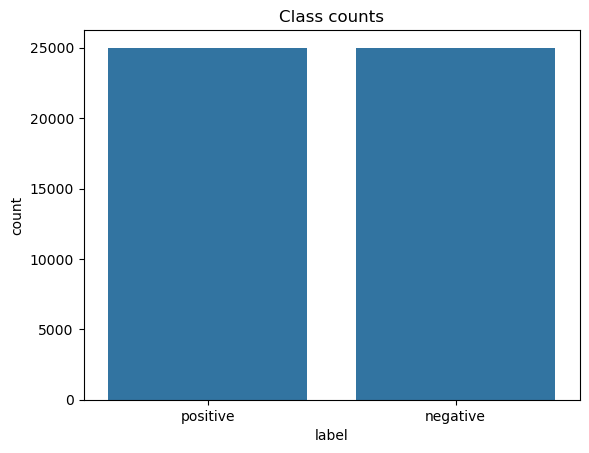

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.countplot(data=df, x="label")
plt.title("Class counts")
plt.show()


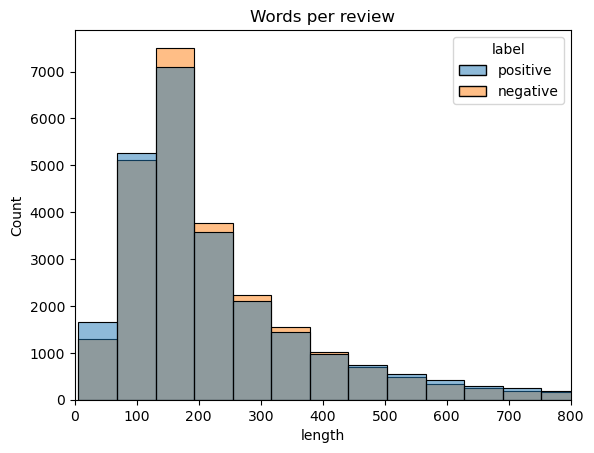

In [6]:
sns.histplot(data=df, x="length", hue="label", bins=40)
plt.xlim(0, 800)
plt.title("Words per review")
plt.show()


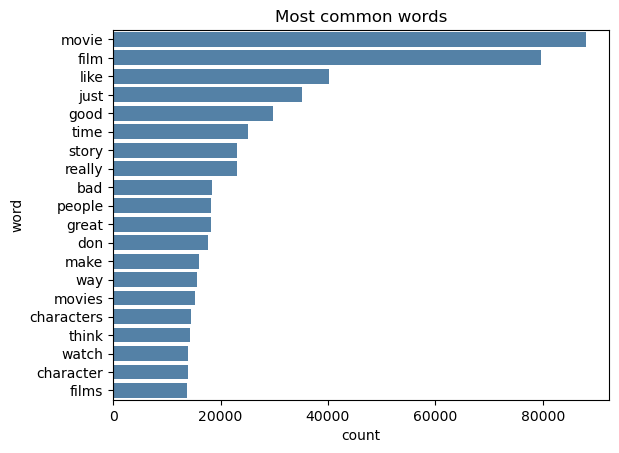

In [7]:
from sklearn.feature_extraction.text import CountVectorizer

vect = CountVectorizer(stop_words="english", max_features=20)
word_counts = vect.fit_transform(df["text"])
top_words = pd.DataFrame({
    "word": vect.get_feature_names_out(),
    "count": word_counts.sum(axis=0).A1,
}).sort_values("count", ascending=False)

sns.barplot(data=top_words, x="count", y="word", color="steelblue")
plt.title("Most common words")
plt.show()


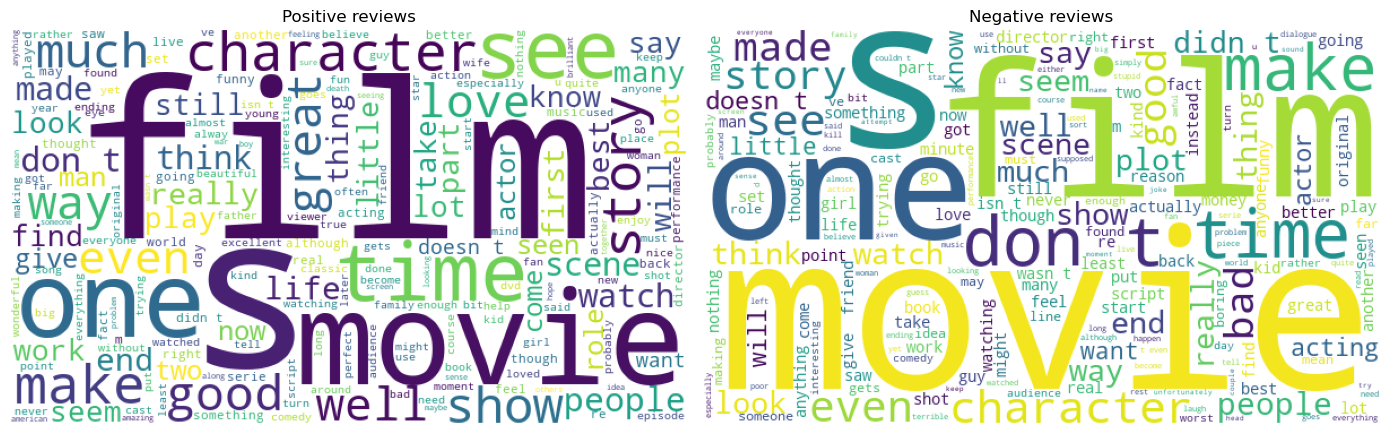

In [8]:
from wordcloud import WordCloud, STOPWORDS

pos_text = " ".join(df.loc[df["label"] == "positive", "text"].astype(str))
neg_text = " ".join(df.loc[df["label"] == "negative", "text"].astype(str))

plt.figure(figsize=(14, 5))
plt.subplot(1, 2, 1)
plt.imshow(WordCloud(width=600, height=350, background_color="white", stopwords=STOPWORDS).generate(pos_text))
plt.title("Positive reviews")
plt.axis("off")
plt.subplot(1, 2, 2)
plt.imshow(WordCloud(width=600, height=350, background_color="white", stopwords=STOPWORDS).generate(neg_text))
plt.title("Negative reviews")
plt.axis("off")
plt.tight_layout()
plt.show()


In [9]:
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import classification_report

x = df["text"]
y = df["label"]
x_train, x_test, y_train, y_test = train_test_split(
    x, y, test_size=0.20, random_state=42, stratify=y
)

lr = Pipeline([
    ("vect", TfidfVectorizer(stop_words="english", max_features=5000)),
    ("model", LogisticRegression(max_iter=1000)),
])
lr.fit(x_train, y_train)
lr_pred = lr.predict(x_test)

print("Logistic Regression")
print(classification_report(y_test, lr_pred))


Logistic Regression
              precision    recall  f1-score   support

    negative       0.90      0.88      0.89      5000
    positive       0.88      0.90      0.89      5000

    accuracy                           0.89     10000
   macro avg       0.89      0.89      0.89     10000
weighted avg       0.89      0.89      0.89     10000



In [10]:
import numpy as np
import tensorflow as tf
from tensorflow.keras import layers
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.preprocessing import LabelEncoder

tf.keras.utils.set_random_seed(42)

le = LabelEncoder()
y_tr = le.fit_transform(y_train)
y_te = le.transform(y_test)

vectorize = layers.TextVectorization(max_tokens=10000, output_sequence_length=200)
vectorize.adapt(x_train.to_numpy())

dl = tf.keras.Sequential([
    vectorize,
    layers.Embedding(10000, 64, mask_zero=True),
    layers.LSTM(64),
    layers.Dropout(0.3),
    layers.Dense(1, activation="sigmoid"),
])
dl.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])
hist = dl.fit(
    x_train.to_numpy(), y_tr,
    validation_split=0.1,
    epochs=6,
    batch_size=128,
    callbacks=[EarlyStopping(patience=2, restore_best_weights=True)],
    verbose=1,
)

dl_pred = (dl.predict(x_test.to_numpy(), verbose=0).ravel() >= 0.5).astype(int)
print("LSTM")
print(classification_report(y_te, dl_pred, target_names=le.classes_))


Epoch 1/6
282/282 ━━━━━━━━━━━━━━━━━━━━ 24s 81ms/step - accuracy: 0.7826 - loss: 0.4448 - val_accuracy: 0.8510 - val_loss: 0.3471
Epoch 2/6
282/282 ━━━━━━━━━━━━━━━━━━━━ 23s 80ms/step - accuracy: 0.8858 - loss: 0.2906 - val_accuracy: 0.8602 - val_loss: 0.3974
Epoch 3/6
282/282 ━━━━━━━━━━━━━━━━━━━━ 22s 79ms/step - accuracy: 0.9029 - loss: 0.2592 - val_accuracy: 0.8702 - val_loss: 0.3495
LSTM
              precision    recall  f1-score   support

    negative       0.80      0.93      0.86      5000
    positive       0.91      0.77      0.84      5000

    accuracy                           0.85     10000
   macro avg       0.86      0.85      0.85     10000
weighted avg       0.86      0.85      0.85     10000



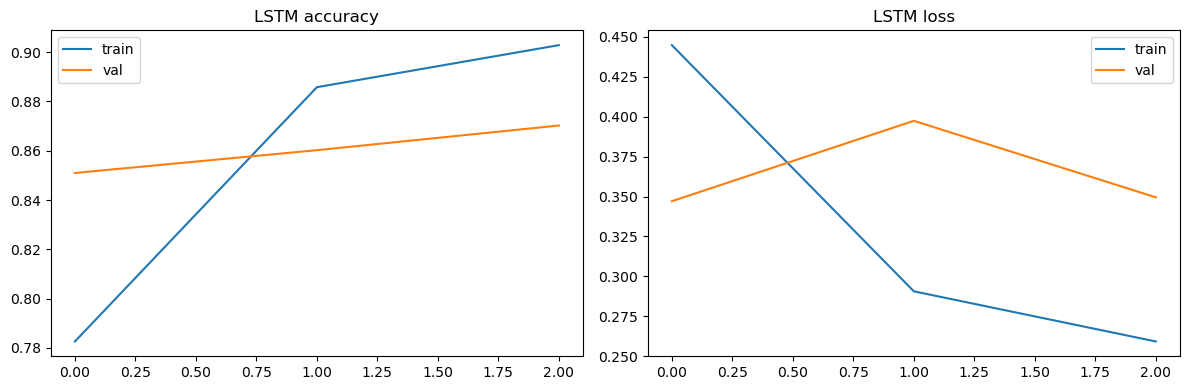

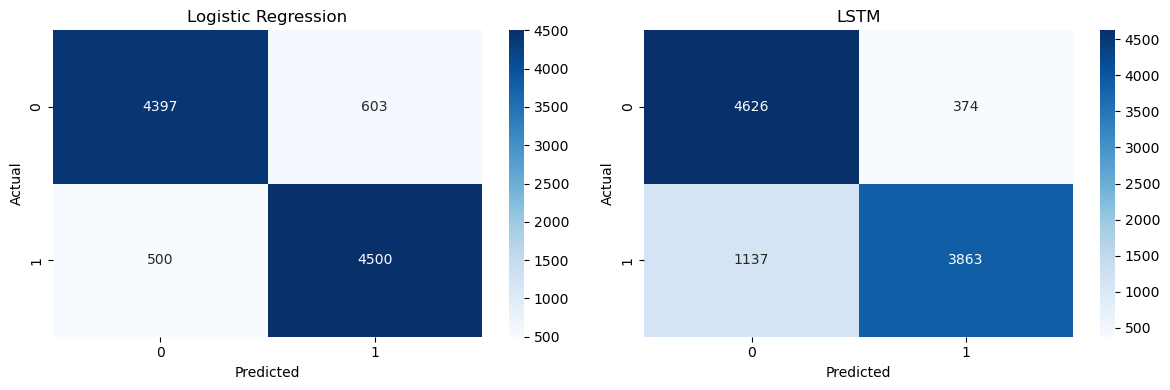

Logistic Regression accuracy 0.8897 F1 0.8908245075720083
LSTM                accuracy 0.8489 F1 0.8364187506766266


In [11]:
from sklearn.metrics import confusion_matrix, f1_score, accuracy_score

plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(hist.history["accuracy"], label="train")
plt.plot(hist.history["val_accuracy"], label="val")
plt.title("LSTM accuracy")
plt.legend()
plt.subplot(1, 2, 2)
plt.plot(hist.history["loss"], label="train")
plt.plot(hist.history["val_loss"], label="val")
plt.title("LSTM loss")
plt.legend()
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.heatmap(confusion_matrix(y_test, lr_pred), annot=True, fmt="d", cmap="Blues", ax=axes[0])
axes[0].set_title("Logistic Regression")
axes[0].set_xlabel("Predicted")
axes[0].set_ylabel("Actual")
sns.heatmap(confusion_matrix(y_te, dl_pred), annot=True, fmt="d", cmap="Blues", ax=axes[1])
axes[1].set_title("LSTM")
axes[1].set_xlabel("Predicted")
axes[1].set_ylabel("Actual")
plt.tight_layout()
plt.show()

print("Logistic Regression accuracy", accuracy_score(y_test, lr_pred), "F1", f1_score(y_test, lr_pred, pos_label="positive"))
print("LSTM                accuracy", accuracy_score(y_te, dl_pred), "F1", f1_score(y_te, dl_pred, pos_label=1))


In [12]:
samples = [
    "the movie was boring and the acting was terrible",
    "i loved this film the story was beautiful and the ending was perfect",
]
print("Logistic Regression", lr.predict(samples))
print("LSTM               ", le.inverse_transform((dl.predict(tf.constant(samples), verbose=0).ravel() >= 0.5).astype(int)))


Logistic Regression ['negative' 'positive']
LSTM                ['negative' 'positive']


In [13]:
dl.save("movie_sentiment.keras")


# Conclusion

Class counts, the twenty most common words and the positive/negative word clouds come first. Logistic Regression on 5000 TF-IDF words is the baseline. The LSTM is the deep learning model: it learns embeddings and reads the review from start to finish. The labels are already balanced, so accuracy and F1 should sit close together. The LSTM is saved as movie_sentiment.keras.
